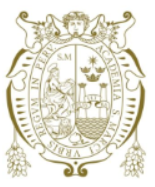

# **UNMSM · Doctoral Program in Deep Tech, Artificial Intelligence & Emerging Technologies**  

## **Course:** Research Methods and Scientific Integrity in AI and Advanced Technologies  
## **Instructor:** Dr. Loveleen Gaur  
## **Student:** MBA, MDS, Eng. Miguel Ángel Patiño Antonioli  

# **DELIVERABLE No. 5 · Reproducible Machine Learning Pipeline**



---





This notebook extends the Session 5 NB4 workshop into a **stranger-proof reproducibility pipeline**. It intentionally uses the public Wisconsin Diagnostic Breast Cancer dataset used in class so that the reproducibility engineering can be audited without inventing thesis data.

### What this notebook proves
- 7 meaningful Git commits (rubric requires 6+).
- Dataset versioned with **DVC** and pushed to a persistent remote.
- A leakage-free `Pipeline`: preprocessing is fitted only inside each training fold.
- Two executions with the same seed return identical output.
- **7 seeds** logged in **MLflow 3.x / SQLite** with mean ± SD.
- Exact direct dependencies in `requirements.txt`.
- `Dockerfile` matches the Python major/minor version used.
- A fresh-clone **stranger test** is included.

> **Reference execution:** Accuracy = **97.842% ± 0.195%** across seven seed-level means; ROC-AUC = **99.515% ± 0.057%**. Re-run the notebook in your Colab environment and use the generated values in GitHub as the authoritative submission.

## Step 0 · Student and repository configuration
Change only `GIT_EMAIL` if needed. The repository and username are prefilled.

In [1]:
STUDENT_NAME = "Miguel Ángel Patiño Antonioli"
GITHUB_USERNAME = "mpatinoantonioli"
REPO_NAME = "UNMSM-Research-Methods-2026-II"
GIT_EMAIL = "mpatinoantonioli@gmail.com"
BRANCH = "main"
D5_FOLDER = "05_Reproducible_ML_Pipeline"
SEEDS = [7, 12, 21, 42, 101, 2026, 3407]
REFERENCE_SEED = 42
print("Configured for:", STUDENT_NAME)
print("Repository:", f"https://github.com/{GITHUB_USERNAME}/{REPO_NAME}")

Configured for: Miguel Ángel Patiño Antonioli
Repository: https://github.com/mpatinoantonioli/UNMSM-Research-Methods-2026-II


## Step 1 · Installation of the tools used by the workflow
MLflow uses a SQLite backend. DVC versions the dataset. `dvc-gdrive` is optional if you choose a native Google Drive DVC URL; the default course path below uses a mounted Drive folder.

In [2]:
!pip -q install "mlflow>=3,<4" "dvc>=3,<4"

import os, sys, json, random, hashlib, platform, subprocess, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import mlflow

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("MLflow:", mlflow.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 101.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 72.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 470.1/470.1 kB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.3/79.3 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 451.2/451.2 kB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11

## Step 2 · Clone the existing course repository and create the D5 skeleton
This preserves my prior Deliverables 1–4 and adds a new folder. The notebook makes a sequence of meaningful commits instead of one bulk upload.

In [3]:
from getpass import getpass
ROOT = Path(f"/content/{REPO_NAME}")
if not ROOT.exists():
    clone_url = f"https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
    subprocess.run(["git","clone",clone_url,str(ROOT)],check=True)
os.chdir(ROOT)
subprocess.run(["git","config","user.name",STUDENT_NAME],check=True)
subprocess.run(["git","config","user.email",GIT_EMAIL],check=True)

D5 = ROOT / D5_FOLDER
for sub in ["data","src","results","figures"]:
    (D5/sub).mkdir(parents=True,exist_ok=True)

# Keep generated stores and secrets out of Git.
gitignore = ROOT / ".gitignore"
existing = gitignore.read_text() if gitignore.exists() else ""
entries = ["__pycache__/", "*.pyc", f"{D5_FOLDER}/mlflow.db", f"{D5_FOLDER}/mlruns/", ".ipynb_checkpoints/"]
with gitignore.open("a") as f:
    for e in entries:
        if e not in existing:
            f.write(e+"\n")
(D5/"README.md").write_text("# Deliverable 05 · Reproducible ML Pipeline\n\nWork in progress.\n", encoding="utf-8")
subprocess.run(["git","add",".gitignore",str(D5/"README.md")],check=True)
subprocess.run(["git","commit","-m","D5-01 Initialize reproducible ML project structure"],check=False)
subprocess.run(["git","log","--oneline","-5"])

CompletedProcess(args=['git', 'log', '--oneline', '-5'], returncode=0)

## Step 3 · Create the exact dataset and fingerprint it
The scikit-learn copy of the UCI Wisconsin Diagnostic Breast Cancer dataset has 569 observations and 30 predictors. We recode **malignant = 1** so precision, recall and F1 refer to the clinically relevant class.

In [4]:
from sklearn.datasets import load_breast_cancer
b = load_breast_cancer(as_frame=True)
df = b.frame.copy()
df["target"] = 1 - df["target"]  # 1 = malignant, 0 = benign
DATA_PATH = D5 / "data" / "breast_cancer.csv"
df.to_csv(DATA_PATH,index=False)
DATA_MD5 = hashlib.md5(DATA_PATH.read_bytes()).hexdigest()
print(df.shape)
print(df["target"].value_counts().rename(index={0:"benign",1:"malignant"}))
print("MD5:", DATA_MD5)


(569, 31)
target
benign       357
malignant    212
Name: count, dtype: int64
MD5: 7d389a2808d8bcf9c30b5933557cdbad


## Step 4 · Version the data with DVC and push it to a persistent remote
**Colab-friendly option:** mount Google Drive and use a dedicated folder as the DVC remote. This satisfies the data-versioning layer without committing the raw dataset to Git.

If `.dvc` already exists because you ran this notebook before, the commands are idempotent. The first Google Drive mount will ask for your authorization.

In [5]:
# Initialize DVC at repository root and track the dataset.
if not (ROOT/".dvc").exists():
    subprocess.run(["dvc","init"],check=True)
subprocess.run(["dvc","add",str(DATA_PATH.relative_to(ROOT))],check=True)

# Persistent remote in your Google Drive.
from google.colab import drive
drive.mount('/content/drive')
DVC_REMOTE = Path('/content/drive/MyDrive/UNMSM_D5_DVC_REMOTE')
DVC_REMOTE.mkdir(parents=True, exist_ok=True)
subprocess.run(["dvc","remote","add","-d","d5drive",str(DVC_REMOTE),"-f"],check=True)
subprocess.run(["dvc","push"],check=True)

# Commit DVC metadata, not the raw CSV.
subprocess.run(["git","add",".dvc",".dvcignore",f"{D5_FOLDER}/data/breast_cancer.csv.dvc",f"{D5_FOLDER}/data/.gitignore"],check=True)
subprocess.run(["git","commit","-m","D5-02 Version dataset with DVC and configure remote"],check=False)
print("DVC remote:", DVC_REMOTE)

Mounted at /content/drive
DVC remote: /content/drive/MyDrive/UNMSM_D5_DVC_REMOTE


## Step 5 · Write the leakage-free training script
Everything that learns from data is inside the scikit-learn `Pipeline`; each scaler is therefore fitted only on the training fold. The seed controls fold shuffling and model randomness.

In [6]:
TRAIN_CODE = r'''"""Leakage-free, seed-controlled evaluation for Deliverable 05.
Run: PYTHONHASHSEED=0 python src/train.py --seed 42
"""
import argparse, hashlib, json, random
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)

def evaluate(seed=42, data_path=None):
    set_seed(seed)
    if data_path is None:
        data_path = Path(__file__).resolve().parents[1] / "data" / "breast_cancer.csv"
    data_path = Path(data_path)
    df = pd.read_csv(data_path)
    X, y = df.drop(columns="target"), df["target"]
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, solver="liblinear", random_state=seed)),
    ])
    scoring = {
        "accuracy":"accuracy",
        "balanced_accuracy":"balanced_accuracy",
        "precision":make_scorer(precision_score, pos_label=1, zero_division=0),
        "recall":make_scorer(recall_score, pos_label=1, zero_division=0),
        "f1":make_scorer(f1_score, pos_label=1, zero_division=0),
        "roc_auc":"roc_auc",
    }
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    raw = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=1, return_train_score=False)
    summary = {"seed":seed, "data_md5":hashlib.md5(data_path.read_bytes()).hexdigest()}
    folds = []
    for fold in range(5):
        row={"seed":seed,"fold":fold+1}
        for metric in scoring:
            vals=raw[f"test_{metric}"]
            row[metric]=float(vals[fold])
            summary[f"{metric}_mean"]=float(vals.mean())
            summary[f"{metric}_sd"]=float(vals.std(ddof=1))
        folds.append(row)
    return summary, pd.DataFrame(folds)

if __name__ == "__main__":
    ap=argparse.ArgumentParser()
    ap.add_argument("--seed",type=int,default=42)
    args=ap.parse_args()
    summary,_=evaluate(args.seed)
    print(json.dumps({k:(round(v,5) if isinstance(v,float) else v) for k,v in summary.items()},sort_keys=True))
'''
(D5/"src"/"train.py").write_text(TRAIN_CODE, encoding="utf-8")
subprocess.run(["git","add",str(D5/"src"/"train.py")],check=True)
subprocess.run(["git","commit","-m","D5-03 Add seeded leakage-free evaluation pipeline"],check=False)
print((D5/"src"/"train.py").read_text()[:1200])

"""Leakage-free, seed-controlled evaluation for Deliverable 05.
Run: PYTHONHASHSEED=0 python src/train.py --seed 42
"""
import argparse, hashlib, json, random
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)

def evaluate(seed=42, data_path=None):
    set_seed(seed)
    if data_path is None:
        data_path = Path(__file__).resolve().parents[1] / "data" / "breast_cancer.csv"
    data_path = Path(data_path)
    df = pd.read_csv(data_path)
    X, y = df.drop(columns="target"), df["target"]
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, solver="liblinear", ra

## Step 6 · Repeatability test: same seed twice
The assignment asks for two runs with the same seed and identical output. We check the full summary and the fold-level scores, not just one rounded number.

In [7]:
sys.path.insert(0, str(D5))
from src.train import evaluate
r1, f1 = evaluate(REFERENCE_SEED)
r2, f2 = evaluate(REFERENCE_SEED)
assert r1 == r2
pd.testing.assert_frame_equal(f1, f2, check_exact=True)
print("PASS ✅ same seed twice -> identical summary and fold metrics")
print(json.dumps({k:(round(v,5) if isinstance(v,float) else v) for k,v in r1.items()}, indent=2))

PASS ✅ same seed twice -> identical summary and fold metrics
{
  "seed": 42,
  "data_md5": "7d389a2808d8bcf9c30b5933557cdbad",
  "accuracy_mean": 0.97542,
  "accuracy_sd": 0.01567,
  "balanced_accuracy_mean": 0.96994,
  "balanced_accuracy_sd": 0.02225,
  "precision_mean": 0.98626,
  "precision_sd": 0.02039,
  "recall_mean": 0.94828,
  "recall_sd": 0.05081,
  "f1_mean": 0.966,
  "f1_sd": 0.02237,
  "roc_auc_mean": 0.99538,
  "roc_auc_sd": 0.00597
}


## Step 7 · MLflow: log seven seeds, code version, data fingerprint and metrics
MLflow is the experiment ledger. The notebook uses a SQLite backend because the Session 5 material explicitly recommends it for MLflow 3.x. Each seed becomes one run.

In [8]:
MLFLOW_DB = D5 / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")
mlflow.set_experiment("UNMSM-D5-reproducibility")
commit = subprocess.run(["git","rev-parse","--short","HEAD"],capture_output=True,text=True,check=True).stdout.strip()

seed_rows=[]; fold_rows=[]
for seed in SEEDS:
    summary, folds = evaluate(seed)
    with mlflow.start_run(run_name=f"seed-{seed}"):
        mlflow.log_params({
            "seed":seed,
            "model":"LogisticRegression(liblinear)",
            "preprocessing":"StandardScaler inside Pipeline",
            "cv":"StratifiedKFold(5, shuffle=True)",
            "git_commit":commit,
            "data_md5":summary["data_md5"],
        })
        metrics={k:v for k,v in summary.items() if k.endswith("_mean") or k.endswith("_sd")}
        mlflow.log_metrics(metrics)
        tmp=D5/"results"/f"fold_metrics_seed_{seed}.csv"
        folds.to_csv(tmp,index=False)
        mlflow.log_artifact(str(tmp), artifact_path="fold_metrics")
    seed_rows.append(summary)
    fold_rows.append(folds)

seed_df=pd.DataFrame(seed_rows)
fold_df=pd.concat(fold_rows,ignore_index=True)
seed_df.to_csv(D5/"results"/"seed_summary.csv",index=False)
fold_df.to_csv(D5/"results"/"fold_metrics_all.csv",index=False)
mlflow_runs = mlflow.search_runs(experiment_names=["UNMSM-D5-reproducibility"])
mlflow_runs.to_csv(D5/"results"/"mlflow_runs_export.csv",index=False)

print(seed_df[["seed","accuracy_mean","accuracy_sd","f1_mean","recall_mean","roc_auc_mean"]].round(5).to_string(index=False))
print("\nAcross-seed report:")
for m in ["accuracy","balanced_accuracy","precision","recall","f1","roc_auc"]:
    v=seed_df[f"{m}_mean"]
    print(f"{m:18s}: {v.mean():.5f} ± {v.std(ddof=1):.5f}")

2026/10/09 21:15:19 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/09 21:15:19 INFO mlflow.store.db.utils: Updating database tables
2026/10/09 21:15:24 INFO mlflow.tracking.fluent: Experiment with name 'UNMSM-D5-reproducibility' does not exist. Creating a new experiment.


 seed  accuracy_mean  accuracy_sd  f1_mean  recall_mean  roc_auc_mean
    7        0.97716      0.01329  0.96901      0.96213       0.99504
   12        0.98067      0.01143  0.97360      0.96213       0.99395
   21        0.97895      0.01468  0.97141      0.96246       0.99539
   42        0.97542      0.01567  0.96600      0.94828       0.99538
  101        0.98067      0.01569  0.97383      0.96678       0.99554
 2026        0.97718      0.01817  0.96861      0.95759       0.99511
 3407        0.97887      0.01483  0.97137      0.96224       0.99561

Across-seed report:
accuracy          : 0.97842 ± 0.00195
balanced_accuracy : 0.97473 ± 0.00263
precision         : 0.98192 ± 0.00323
recall            : 0.96023 ± 0.00590
f1                : 0.97055 ± 0.00284
roc_auc           : 0.99515 ± 0.00057


### Reference results from the prepared deliverable
Using Python 3.13.5 and scikit-learn 1.8.0, the same evaluation logic produced:

| Metric | Across-seed mean ± SD |
|---|---:|
| Accuracy | **0.97842 ± 0.00195** |
| Balanced accuracy | **0.97473 ± 0.00263** |
| Precision (malignant) | **0.98192 ± 0.00323** |
| Recall / sensitivity (malignant) | **0.96023 ± 0.00590** |
| F1 (malignant) | **0.97055 ± 0.00284** |
| ROC-AUC | **0.99515 ± 0.00057** |

The clinically relevant insight is that **recall varied the most across seeds** (about 1.85 percentage points from minimum to maximum), while ROC-AUC was the most stable. This is why one hero seed is not a scientifically complete report.

## Step 8 · Visualize seed sensitivity and save artifacts

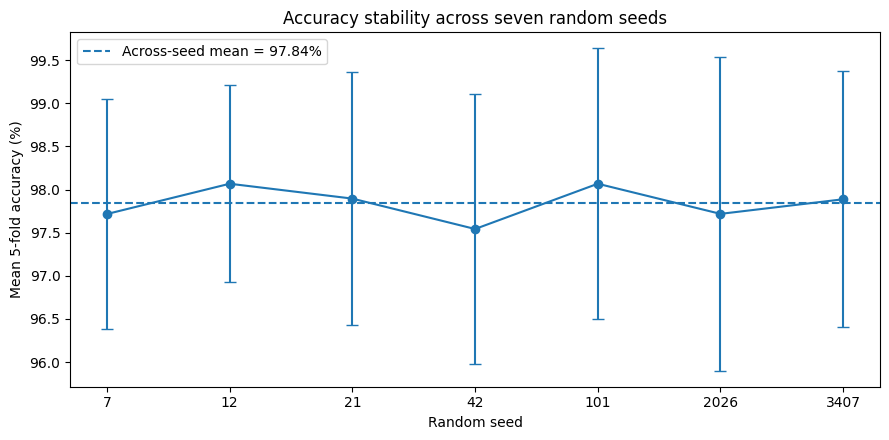

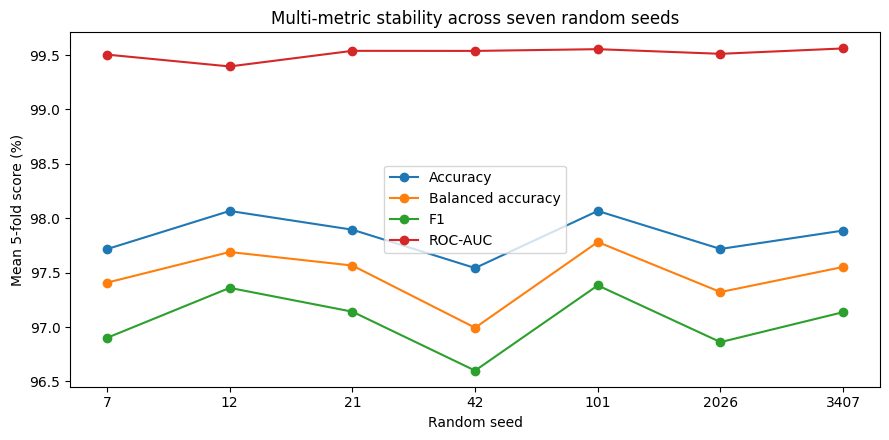

CompletedProcess(args=['git', 'commit', '-m', 'D5-04 Log seven-seed results and reproducibility figures'], returncode=0)

In [9]:
plt.figure(figsize=(9,4.5))
plt.errorbar(seed_df["seed"].astype(str), seed_df["accuracy_mean"]*100,
             yerr=seed_df["accuracy_sd"]*100, marker="o", capsize=4)
mean_acc=seed_df["accuracy_mean"].mean()*100
plt.axhline(mean_acc,linestyle="--",label=f"Across-seed mean = {mean_acc:.2f}%")
plt.xlabel("Random seed"); plt.ylabel("Mean 5-fold accuracy (%)")
plt.title("Accuracy stability across seven random seeds"); plt.legend(); plt.tight_layout()
plt.savefig(D5/"figures"/"accuracy_by_seed.png",dpi=200); plt.show()

plt.figure(figsize=(9,4.5))
for col,label in [("accuracy_mean","Accuracy"),("balanced_accuracy_mean","Balanced accuracy"),("f1_mean","F1"),("roc_auc_mean","ROC-AUC")]:
    plt.plot(seed_df["seed"].astype(str), seed_df[col]*100, marker="o", label=label)
plt.xlabel("Random seed"); plt.ylabel("Mean 5-fold score (%)")
plt.title("Multi-metric stability across seven random seeds"); plt.legend(); plt.tight_layout()
plt.savefig(D5/"figures"/"metrics_by_seed.png",dpi=200); plt.show()

subprocess.run(["git","add",str(D5/"results"),str(D5/"figures")],check=True)
subprocess.run(["git","commit","-m","D5-04 Log seven-seed results and reproducibility figures"],check=False)

## Step 9 · Freeze the direct environment and generate the Dockerfile
The course explicitly warns against `pip freeze` in Colab. We pin only direct dependencies that this workflow uses, and generate a Docker base image matching the Python major/minor version.

In [10]:
import importlib.metadata as md
packages=["numpy","pandas","scikit-learn","matplotlib","mlflow","dvc"]
with (D5/"requirements.txt").open("w") as f:
    for pkg in packages:
        f.write(f"{pkg}=={md.version(pkg)}\n")
py_mm=".".join(platform.python_version().split(".")[:2])
docker=f'''FROM python:{py_mm}-slim
ENV PYTHONHASHSEED=0
WORKDIR /app
COPY {D5_FOLDER}/requirements.txt /app/requirements.txt
RUN pip install --no-cache-dir -r /app/requirements.txt
COPY {D5_FOLDER} /app/{D5_FOLDER}
CMD ["python", "/app/{D5_FOLDER}/src/train.py", "--seed", "42"]
'''
(D5/"Dockerfile").write_text(docker,encoding="utf-8")
subprocess.run(["git","add",str(D5/"requirements.txt"),str(D5/"Dockerfile")],check=True)
subprocess.run(["git","commit","-m","D5-05 Pin direct dependencies and add matching Dockerfile"],check=False)
print((D5/"requirements.txt").read_text())
print((D5/"Dockerfile").read_text())

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
mlflow==3.17.0
dvc==3.67.1

FROM python:3.13-slim
ENV PYTHONHASHSEED=0
WORKDIR /app
COPY 05_Reproducible_ML_Pipeline/requirements.txt /app/requirements.txt
RUN pip install --no-cache-dir -r /app/requirements.txt
COPY 05_Reproducible_ML_Pipeline /app/05_Reproducible_ML_Pipeline
CMD ["python", "/app/05_Reproducible_ML_Pipeline/src/train.py", "--seed", "42"]



## Step 10 · Build the stranger-proof README
The README contains the exact commands, data fingerprint, expected seed-42 output, and the seven-seed headline result.

In [11]:
seed42=seed_df.loc[seed_df.seed==42].iloc[0]
acc=seed_df.accuracy_mean
readme=f'''# Deliverable 05 — Reproducible ML Pipeline

**Student:** {STUDENT_NAME}
**Course:** Research Methods and Scientific Integrity in AI and Advanced Technologies — UNMSM

## Objective
Demonstrate a leakage-free, versioned and auditable ML experiment. The public Wisconsin Diagnostic Breast Cancer dataset is used because it is the Session 5 workshop dataset; `target=1` denotes malignant disease.

## Reproducibility stack
- **Code:** Git / GitHub
- **Data:** DVC + persistent remote
- **Experiments:** MLflow 3.x with SQLite
- **Environment:** pinned direct dependencies + Dockerfile
- **Reporting:** seven seeds, mean ± SD, figures and exact expected output

## Reproduce
```bash
git clone https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git
cd {REPO_NAME}
dvc pull
pip install -r {D5_FOLDER}/requirements.txt
PYTHONHASHSEED=0 python {D5_FOLDER}/src/train.py --seed 42
```

## Expected seed-42 result
- accuracy_mean = {seed42.accuracy_mean:.5f}
- accuracy_sd = {seed42.accuracy_sd:.5f}
- f1_mean = {seed42.f1_mean:.5f}
- recall_mean = {seed42.recall_mean:.5f}
- roc_auc_mean = {seed42.roc_auc_mean:.5f}
- data_md5 = `{DATA_MD5}`

## Seven-seed headline result
Accuracy = **{acc.mean():.5f} ± {acc.std(ddof=1):.5f}** across seed-level 5-fold means.
See `results/seed_summary.csv` and `figures/` for the full audit trail.

## Repeatability check
Run the seed-42 command twice. The JSON line must be identical. The notebook also asserts equality of every fold-level metric.

## Docker
After `dvc pull`:
```bash
docker build -f {D5_FOLDER}/Dockerfile -t unmsm-d5-repro .
docker run --rm unmsm-d5-repro
```

## Data source
Wisconsin Diagnostic Breast Cancer dataset, UCI Machine Learning Repository (CC BY 4.0).
'''
(D5/"README.md").write_text(readme,encoding="utf-8")
subprocess.run(["git","add",str(D5/"README.md")],check=True)
subprocess.run(["git","commit","-m","D5-06 Document exact stranger-test reproduction recipe"],check=False)
print(readme)

# Deliverable 05 — Reproducible ML Pipeline

**Student:** Miguel Ángel Patiño Antonioli  
**Course:** Research Methods and Scientific Integrity in AI and Advanced Technologies — UNMSM  

## Objective
Demonstrate a leakage-free, versioned and auditable ML experiment. The public Wisconsin Diagnostic Breast Cancer dataset is used because it is the Session 5 workshop dataset; `target=1` denotes malignant disease.

## Reproducibility stack
- **Code:** Git / GitHub
- **Data:** DVC + persistent remote
- **Experiments:** MLflow 3.x with SQLite
- **Environment:** pinned direct dependencies + Dockerfile
- **Reporting:** seven seeds, mean ± SD, figures and exact expected output

## Reproduce
```bash
git clone https://github.com/mpatinoantonioli/UNMSM-Research-Methods-2026-II.git
cd UNMSM-Research-Methods-2026-II
dvc pull
pip install -r 05_Reproducible_ML_Pipeline/requirements.txt
PYTHONHASHSEED=0 python 05_Reproducible_ML_Pipeline/src/train.py --seed 42
```

## Expected seed-42 result
- accuracy_

## Step 11 · Add a machine-readable reproducibility manifest
This extra artifact makes the result auditable without reading prose.

In [12]:
manifest={
    "student":STUDENT_NAME,
    "reference_seed":REFERENCE_SEED,
    "seeds":SEEDS,
    "data_md5":DATA_MD5,
    "python":platform.python_version(),
    "scikit_learn":sklearn.__version__,
    "mlflow":mlflow.__version__,
    "headline_accuracy_mean":float(seed_df.accuracy_mean.mean()),
    "headline_accuracy_sd_across_seeds":float(seed_df.accuracy_mean.std(ddof=1)),
}
(D5/"reproducibility_manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
subprocess.run(["git","add",str(D5/"reproducibility_manifest.json")],check=True)
subprocess.run(["git","commit","-m","D5-07 Add machine-readable reproducibility manifest"],check=False)
print(json.dumps(manifest,indent=2))

{
  "student": "Miguel \u00c1ngel Pati\u00f1o Antonioli",
  "reference_seed": 42,
  "seeds": [
    7,
    12,
    21,
    42,
    101,
    2026,
    3407
  ],
  "data_md5": "7d389a2808d8bcf9c30b5933557cdbad",
  "python": "3.13.16",
  "scikit_learn": "1.6.1",
  "mlflow": "3.17.0",
  "headline_accuracy_mean": 0.9784172821434117,
  "headline_accuracy_sd_across_seeds": 0.001945931521096962
}


## Step 12 · Audit the Git story before pushing
You should see **7 D5 commits** with clear messages. This exceeds the 6+ commit requirement in the final Session 5 rubric.

In [13]:
log=subprocess.run(["git","log","--oneline","--all","-20"],capture_output=True,text=True,check=True).stdout
print(log)
d5_commits=[line for line in log.splitlines() if "D5-" in line]
print("D5 commits found:",len(d5_commits))
assert len(d5_commits) >= 7

f01704c D5-07 Add machine-readable reproducibility manifest
d4ab01f D5-06 Document exact stranger-test reproduction recipe
cfc46d8 D5-05 Pin direct dependencies and add matching Dockerfile
318ab53 D5-04 Log seven-seed results and reproducibility figures
83d9492 D5-03 Add seeded leakage-free evaluation pipeline
7e735e9 D5-02 Version dataset with DVC and configure remote
e4667dc D5-01 Initialize reproducible ML project structure
3faa752 Add files via upload
cd147ec Create Deliverable 04 folder
8d4f691 Update README.md
40addca Update repository with Deliverable 03
1cba785 Upload Deliverable 03 Research Protocol
652e6bf Create Deliverable 03 Research Protocol folder
1965d91 Update main repository README
10801dd Add files via upload
25fb06d Create Deliverable 02 folder and README
f25a0dd Add files via upload
2f0c3a9 Create Deliverable 01 folder and README
23b6d3d Initial commit

D5 commits found: 7


## Step 13 · Push all commits to GitHub safely
Create a **fine-grained GitHub token** with `Contents: Read and write`. The token is requested in a hidden prompt, used for this push only, and is not stored in Git configuration.

In [15]:
import os
import subprocess
from pathlib import Path
from getpass import getpass

# Asegurarnos de estar dentro del repositorio
os.chdir(ROOT)

print("Repository:", ROOT)
print("Branch:", BRANCH)

# El token se introduce de forma oculta
token = getpass("GitHub token (hidden): ")

# Git AskPass temporal para NO poner el token en la URL
askpass_file = Path("/tmp/git_askpass.sh")

askpass_file.write_text(
    """#!/bin/sh
case "$1" in
    *Username*) echo "$GIT_USERNAME" ;;
    *Password*) echo "$GITHUB_TOKEN" ;;
esac
"""
)

os.chmod(askpass_file, 0o700)

env = os.environ.copy()
env["GIT_USERNAME"] = GITHUB_USERNAME
env["GITHUB_TOKEN"] = token
env["GIT_ASKPASS"] = str(askpass_file)
env["GIT_TERMINAL_PROMPT"] = "0"

repo_url = f"https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"

result = subprocess.run(
    ["git", "push", repo_url, BRANCH],
    cwd=str(ROOT),
    env=env,
    text=True,
    capture_output=True
)

# Borrar credenciales temporales
askpass_file.unlink(missing_ok=True)
del token
env.pop("GITHUB_TOKEN", None)

print(result.stdout)

if result.returncode == 0:
    print("✅ PUSH SUCCESSFUL")
    print(
        f"https://github.com/{GITHUB_USERNAME}/"
        f"{REPO_NAME}/tree/{BRANCH}/{D5_FOLDER}"
    )
else:
    print("❌ PUSH FAILED")
    print(result.stderr)

Repository: /content/UNMSM-Research-Methods-2026-II
Branch: main
GitHub token (hidden): ··········

✅ PUSH SUCCESSFUL
https://github.com/mpatinoantonioli/UNMSM-Research-Methods-2026-II/tree/main/05_Reproducible_ML_Pipeline


## Step 14 · Fresh-clone stranger test
Run this **after pushing**. It clones the repository into a clean directory and reproduces the seed-42 result. Because the DVC remote is in your Google Drive, this fresh clone works in the same authorized Colab session. A genuinely independent reviewer would need read access to that remote.

In [16]:
RUN_STRANGER_TEST = True
if RUN_STRANGER_TEST:
    TESTROOT=Path('/content/stranger-test')
    shutil.rmtree(TESTROOT,ignore_errors=True)
    subprocess.run(["git","clone",f"https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git",str(TESTROOT)],check=True)
    os.chdir(TESTROOT)
    # Google Drive is already mounted in this Colab session.
    subprocess.run(["dvc","pull"],check=True)
    cmd=["bash","-lc",f"PYTHONHASHSEED=0 python {D5_FOLDER}/src/train.py --seed 42"]
    out=subprocess.run(cmd,capture_output=True,text=True,check=True).stdout.strip()
    print("Fresh-clone output:",out)
    assert f'"accuracy_mean": {seed42.accuracy_mean:.5f}' in out
    print("STRANGER TEST PASS ✅")
    os.chdir(ROOT)
else:
    print("Set RUN_STRANGER_TEST=True after the GitHub push.")

Fresh-clone output: {"accuracy_mean": 0.97542, "accuracy_sd": 0.01567, "balanced_accuracy_mean": 0.96994, "balanced_accuracy_sd": 0.02225, "data_md5": "7d389a2808d8bcf9c30b5933557cdbad", "f1_mean": 0.966, "f1_sd": 0.02237, "precision_mean": 0.98626, "precision_sd": 0.02039, "recall_mean": 0.94828, "recall_sd": 0.05081, "roc_auc_mean": 0.99538, "roc_auc_sd": 0.00597, "seed": 42}
STRANGER TEST PASS ✅


## Final self-check
- [ ] 7 D5 commits visible on GitHub.
- [ ] `dvc status` is clean and `dvc push` succeeded.
- [ ] Same seed twice gave identical output.
- [ ] Seven seed runs appear in MLflow and `results/seed_summary.csv`.
- [ ] `requirements.txt` contains only pinned direct dependencies.
- [ ] Dockerfile Python major/minor matches the Colab runtime.
- [ ] README alone gives the commands and expected number.
- [ ] Fresh-clone stranger test passes.

### Scientific conclusion
A single fixed seed is **necessary but insufficient**. In this reference execution, accuracy was stable (range ≈ 0.52 percentage points across seeds), but malignant-class recall moved by ≈ 1.85 percentage points. Reporting only one seed would hide that uncertainty. The defensible result is therefore the **distribution across seeds**, together with versioned code, data, environment and experiment metadata.